In [ ]:

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Generate synthetic pollutant data
n_samples = 2000

X = np.random.uniform(
    low=[5, 10, 5, 2, 0.1, 5],
    high=[250, 400, 150, 100, 10, 150],
    size=(n_samples, 6)
)

# Features: PM2.5, PM10, NO2, SO2, CO, O3
# Create a synthetic AQI-like score
aqi_score = (
    0.45 * X[:, 0] +
    0.20 * X[:, 1] +
    0.15 * X[:, 2] +
    0.10 * X[:, 3] +
    2.0 * X[:, 4] +
    0.10 * X[:, 5]
)

# Convert scores into 4 classes
y = np.digitize(aqi_score, bins=[50, 100, 150])

print("Dataset generated successfully!")
print("Features shape:", X.shape)
print("Labels shape:", y.shape)


Dataset generated successfully!
Features shape: (2000, 6)
Labels shape: (2000,)


In [ ]:

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_test = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: torch.Size([1600, 1, 6])
Testing data: torch.Size([400, 1, 6])


In [ ]:

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv1d(1, 16, kernel_size=2)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(2)

        self.fc1 = nn.Linear(32, 16)
        self.fc2 = nn.Linear(16, 4)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = SimpleCNN()

print(model)


SimpleCNN(
  (conv1): Conv1d(1, 16, kernel_size=(2,), stride=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=4, bias=True)
)


In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 20

train_losses = []

for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {loss.item():.4f}"
    )

print("Training completed!")


Epoch [1/20], Loss: 1.4290
Epoch [2/20], Loss: 1.4193
Epoch [3/20], Loss: 1.4099
Epoch [4/20], Loss: 1.4007
Epoch [5/20], Loss: 1.3917
Epoch [6/20], Loss: 1.3829
Epoch [7/20], Loss: 1.3742
Epoch [8/20], Loss: 1.3657
Epoch [9/20], Loss: 1.3574
Epoch [10/20], Loss: 1.3492
Epoch [11/20], Loss: 1.3412
Epoch [12/20], Loss: 1.3334
Epoch [13/20], Loss: 1.3258
Epoch [14/20], Loss: 1.3184
Epoch [15/20], Loss: 1.3112
Epoch [16/20], Loss: 1.3042
Epoch [17/20], Loss: 1.2974
Epoch [18/20], Loss: 1.2907
Epoch [19/20], Loss: 1.2843
Epoch [20/20], Loss: 1.2779
Training completed!


In [ ]:

model.eval()

with torch.no_grad():
    outputs = model(X_test)
    predictions = torch.argmax(outputs, dim=1)

accuracy = accuracy_score(
    y_test.numpy(),
    predictions.numpy()
)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test.numpy(),
        predictions.numpy(),
        zero_division=0
    )
)


Test Accuracy: 51.75 %

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.00      0.00      0.00        85
           2       0.47      0.98      0.64       173
           3       0.93      0.27      0.42       137

    accuracy                           0.52       400
   macro avg       0.35      0.31      0.26       400
weighted avg       0.52      0.52      0.42       400



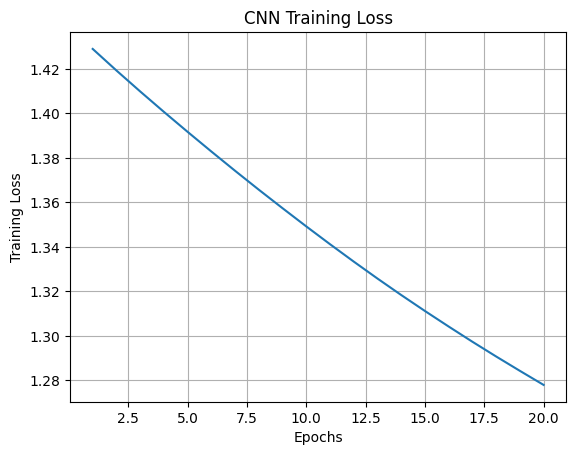

In [ ]:

import matplotlib.pyplot as plt

plt.plot(range(1, epochs + 1), train_losses)
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.grid(True)
plt.show()
